<h1 align="center">Анализ клиентов сети фитнес-центров</h1>

<p align="center">
  <b>Прогнозирование оттока · Сегментация клиентов · Рекомендации по удержанию</b>
</p>

---

# О проекте

Сеть фитнес-центров «Культурист-дата-сайентист» разрабатывает стратегию взаимодействия с клиентами на основе аналитических данных. Главная проблема — **отток**: клиенты редко уходят демонстративно, чаще они просто тихо перестают ходить в зал.

> **Определение оттока.** Клиент считается ушедшим, если за последний месяц он **ни разу не посетил спортзал**. Бывает, что человек уезжал в отпуск и вернётся, но чаще такое отсутствие означает окончательный уход.

**Цели исследования**

1. Научиться прогнозировать вероятность оттока (на уровне следующего месяца) для каждого клиента.
2. Выделить типичные портреты клиентов и охарактеризовать их главные свойства.
3. Выяснить, какие признаки сильнее всего влияют на отток.
4. Сформулировать выводы и рекомендации по удержанию: определить целевые группы и меры по снижению оттока.

# Данные

Файл `gym_churn.csv` содержит анкетные данные клиентов **за месяц до проверки факта оттока** и сам факт оттока (4000 клиентов, 14 признаков).

Набор данных включает следующие поля:

- `Churn` — факт оттока в текущем месяце.

- Данные пользователя за месяц до проверки факта оттока:

   - `gender`  — пол: `1` — женский, `0` — мужской.

   - `Near_Location` — проживание или работа в районе фитнес-центра: `1` — да, `0` — нет.

   - `Partner` — сотрудник компании — партнёра клуба (может получить корпоративную скидку): `1` — да, `0` — нет.

   - `Promo_friends` — запись по акции «Приведи друга» (использован промокод): `1` — да, `0` — нет.

   - `Phone` — наличие контактного телефона: `1` — да, `0` — нет.

   - `Age` — возраст.

   - `Lifetime` — время с момента первого обращения в фитнес-центр в месяцах.

- Информация на основе журнала посещений, покупок и информация о текущем статусе абонемента клиента:

   - `Contract_period` — длительность текущего действующего абонемента (1, 3, 6 или 12 месяцев).

   - `Month_to_end_contract` — срок до окончания текущего действующего абонемента в месяцах.

   - `Group_visits` — факт посещения групповых занятий.

   - `Avg_class_frequency_total` — средняя частота посещений в неделю за всё время с начала действия абонемента.

   - `Avg_class_frequency_current_month` — средняя частота посещений в неделю за предыдущий месяц.

   - `Avg_additional_charges_total` — суммарная выручка от других услуг фитнес-центра: кафе, спорттовары, косметический и массажный салоны.

# План работы

1. **Загрузка данных**
2. **Исследовательский анализ (EDA)** — качество данных, сравнение «ушли / остались», корреляции
3. **Модель прогнозирования оттока** — Random Forest, метрики accuracy / precision / recall
4. **Кластеризация клиентов** — стандартизация, дендрограмма, K-Means (5 кластеров)
5. **Выводы и рекомендации** по удержанию клиентов

---

## Подготовка окружения

In [1]:
import os

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, set_link_color_palette
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Единое значение для воспроизводимости: разбиение, случайный лес, K-Means
RANDOM_STATE = 0

# Настройки отображения
pd.set_option("display.precision", 2)
pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", 300)

# Папка для графиков (они используются в README)
os.makedirs("images", exist_ok=True)


def save_fig(name):
    """Сохраняет текущий график в images/."""
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

In [2]:
# Базовая палитра
VLAG = sns.color_palette("vlag", as_cmap=True)


def vc(x):
    """Цвет из палитры vlag по позиции 0-1."""
    return to_hex(VLAG(x))


BLUE = vc(0.18)    # остался (холодный край)
RED = vc(0.82)     # ушёл (тёплый край)
SOFT_B = vc(0.35)  # светло-синий
SOFT_R = vc(0.65)  # светло-красный
MID = vc(0.50)     # нейтральный центр

CHURN_PAL = {0: BLUE, 1: RED}

## Загрузка данных

In [3]:
# Локальный файл; если его нет — загружаем по ссылке заказчика
DATA_PATH = "data/gym_churn.csv"
DATA_URL = "https://code.s3.yandex.net/datasets/gym_churn.csv"

df = pd.read_csv(DATA_PATH if os.path.exists(DATA_PATH) else DATA_URL)

print("=" * 40)
print("Общая информация о данных")
print("=" * 40)
print(f"{'Строк:':<20} {df.shape[0]}")
print(f"{'Столбцов:':<20} {df.shape[1]}")
print("=" * 40 + "\n")

# Проверяем типы данных и наличие пропусков
df.info()

print("\n" + "=" * 40)
print("Первые 5 строк датафрейма")
print("=" * 40)
display(df.head())

Общая информация о данных
Строк:               4000
Столбцов:            14

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.23,5.0,3,0.02,0.00,0
1,0,1,0,0,1,12,1,31,113.20,12.0,7,1.92,1.91,0
2,0,1,1,0,1,1,0,28,129.45,1.0,2,1.86,1.74,0
3,0,1,1,1,1,12,1,33,62.67,12.0,2,3.21,3.36,0
4,1,1,1,1,1,1,0,26,198.36,1.0,3,1.11,1.12,0


## Исследовательский анализ данных (EDA)

Что проверяем:

- есть ли пропуски и дубликаты, каковы средние значения и разброс признаков (`describe()`);
- как различаются средние значения признаков у ушедших и оставшихся клиентов (`groupby()`);
- как признаки связаны между собой и с оттоком (матрица корреляций).

### Качество данных и общая статистика

In [4]:
print("=" * 40)
print("Качество данных")
print("=" * 40)
print(f"{'Пропусков:':<20} {df.isna().sum().sum()}")
print(f"{'Дубликатов:':<20} {df.duplicated().sum()}")
print("-" * 40)

print("\nСтатистика по числовым признакам")
print("=" * 40)
display(df.describe().T.style.format("{:.2f}"))

Качество данных
Пропусков:           0
Дубликатов:          0
----------------------------------------

Статистика по числовым признакам


,count,mean,std,min,25%,50%,75%,max
gender,4000.00,0.51,0.50,0.00,0.00,1.00,1.00,1.00
Near_Location,4000.00,0.85,0.36,0.00,1.00,1.00,1.00,1.00
Partner,4000.00,0.49,0.50,0.00,0.00,0.00,1.00,1.00
Promo_friends,4000.00,0.31,0.46,0.00,0.00,0.00,1.00,1.00
Phone,4000.00,0.90,0.30,0.00,1.00,1.00,1.00,1.00
Contract_period,4000.00,4.68,4.55,1.00,1.00,1.00,6.00,12.00
Group_visits,4000.00,0.41,0.49,0.00,0.00,0.00,1.00,1.00
Age,4000.00,29.18,3.26,18.00,27.00,29.00,31.00,41.00
Avg_additional_charges_total,4000.00,146.94,96.36,0.15,68.87,136.22,210.95,552.59
Month_to_end_contract,4000.00,4.32,4.19,1.00,1.00,1.00,6.00,12.00


In [5]:
# Проверяем баланс классов целевой переменной
print("=" * 40)
print("Баланс классов целевой переменной Churn")
print("=" * 40)

churn_share = df["Churn"].value_counts(normalize=True).sort_index()

display(
    churn_share.rename(index={0: "Остались", 1: "Ушли"})
    .mul(100)
    .to_frame(name="Доля, %")
    .style.format("{:.2f}%")
)

Баланс классов целевой переменной Churn


,"Доля, %"
Остались,73.47%
Ушли,26.52%


### Ушедшие и оставшиеся клиенты

In [6]:
print("=" * 50)
print("Средние значения признаков по группам оттока")
print("=" * 50)
display(
    df.groupby("Churn")
    .mean()
    .T
    .rename(columns={0: "Остался (0)", 1: "Ушёл (1)"})
    .style.format("{:.2f}")
)

Средние значения признаков по группам оттока


Churn,Остался (0),Ушёл (1)
gender,0.51,0.51
Near_Location,0.87,0.77
Partner,0.53,0.36
Promo_friends,0.35,0.18
Phone,0.90,0.90
Contract_period,5.75,1.73
Group_visits,0.46,0.27
Age,29.98,26.99
Avg_additional_charges_total,158.45,115.08
Month_to_end_contract,5.28,1.66


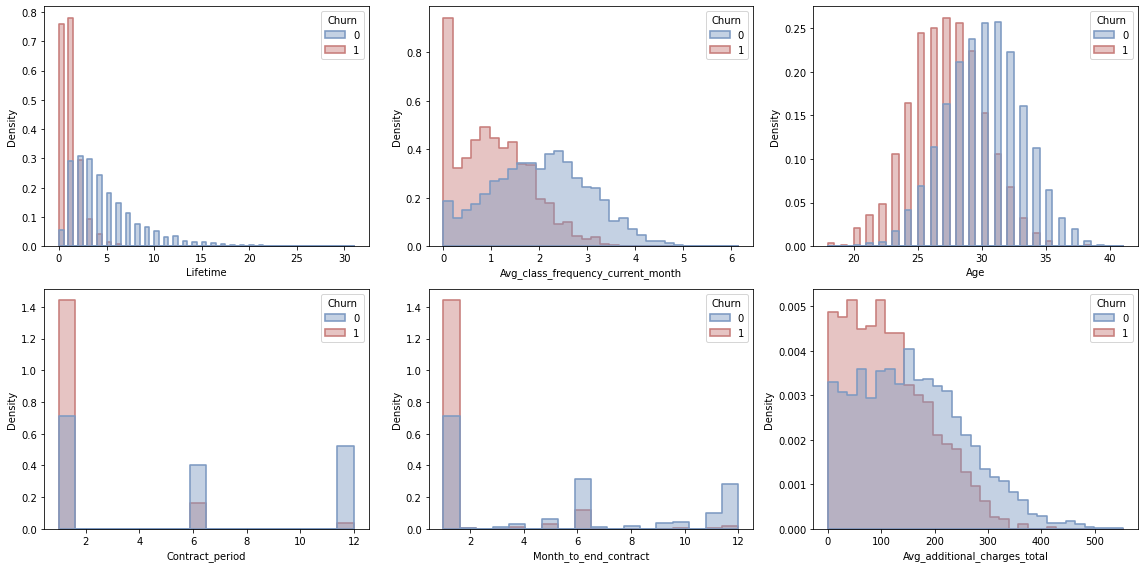

In [7]:
# Распределения ключевых признаков в двух группах
# (нормировка по плотности, чтобы честно сравнивать группы разного размера)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

features = [
    "Lifetime", "Avg_class_frequency_current_month", "Age",
    "Contract_period", "Month_to_end_contract", "Avg_additional_charges_total",
]

for ax, col in zip(axes.flat, features):
    sns.histplot(
        data=df,
        x=col,
        hue="Churn",
        stat="density",
        common_norm=False,
        element="step",
        palette=CHURN_PAL,
        alpha=0.45,
        linewidth=1.6,
        ax=ax,
    )

plt.tight_layout()
save_fig("01_distributions")
plt.show()

### Матрица корреляций

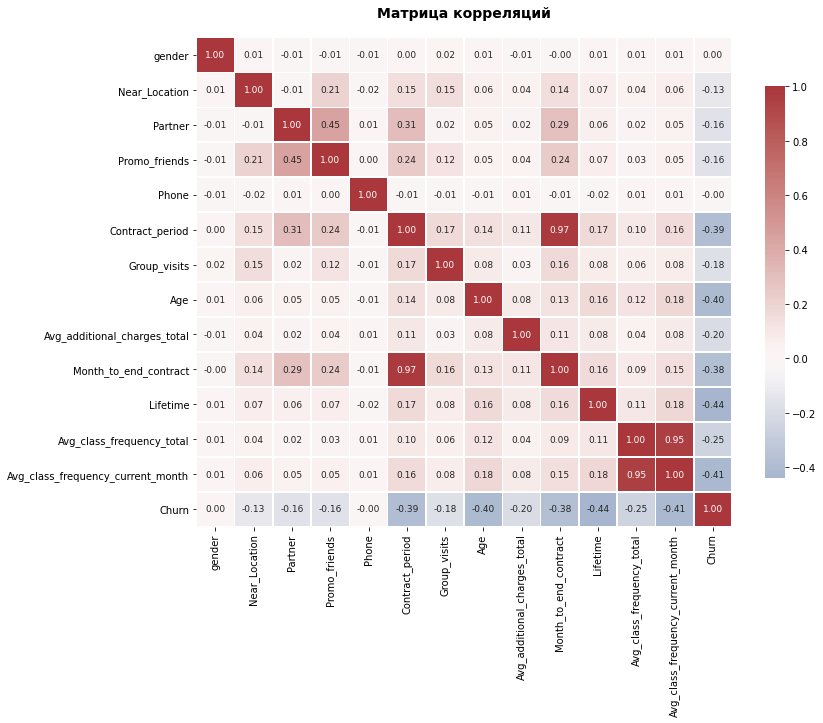

In [8]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    linewidths=0.6,
    linecolor="white",
    annot_kws={"size": 9},
    cbar_kws={"shrink": 0.8},
)

plt.title("Матрица корреляций", fontsize=14, pad=20, fontweight="bold")
save_fig("02_correlation_matrix")
plt.show()

---
<b>Промежуточные выводы по EDA</b>

1. Качество данных

<table border="1" cellpadding="6" cellspacing="0" style="border-collapse: collapse; width: 100%;">
  <tr style="background-color:#f2f2f2;">
    <th>Показатель</th>
    <th>Значение</th>
  </tr>
  <tr><td>Пропуски</td><td>✅ отсутствуют</td></tr>
  <tr><td>Дубликаты</td><td>✅ отсутствуют</td></tr>
  <tr><td>Доля оттока</td><td>26.5% (~1 из 4 клиентов)</td></tr>
</table>

2. Портрет ушедшего клиента

<table border="1" cellpadding="6" cellspacing="0" style="border-collapse: collapse; width: 100%;">
  <tr style="background-color:#f2f2f2;">
    <th>Признак</th>
    <th>Ушедшие</th>
    <th>Оставшиеся</th>
  </tr>
  <tr><td>Длина абонемента</td><td>~1.7 мес.</td><td>~5.7 мес.</td></tr>
  <tr><td>Lifetime</td><td>~1 мес.</td><td>~4.7 мес.</td></tr>
  <tr><td>Возраст</td><td>~27 лет</td><td>~30 лет</td></tr>
  <tr><td>Частота посещений (последний месяц)</td><td>1.04 раза/нед.</td><td>2.03 раза/нед.</td></tr>
  <tr><td>Срок до конца абонемента</td><td colspan="2">малый</td></tr>
</table>

3. Факторы, снижающие отток

<ul>
  <li>пришёл от <b>партнёра</b>;</li>
  <li>пришёл по акции <b>«Приведи друга»</b>;</li>
  <li>посещает <b>групповые занятия</b>;</li>
  <li>живёт или работает <b>рядом с залом</b>.</li>
</ul>

4. Признаки, не влияющие на отток

<ul>
  <li><b>Пол</b> — корреляция ≈ 0;</li>
  <li><b>Наличие телефона</b> — корреляция ≈ 0.</li>
</ul>

5. Мультиколлинеарность

<table border="1" cellpadding="6" cellspacing="0" style="border-collapse: collapse; width: 100%;">
  <tr style="background-color:#f2f2f2;">
    <th>Пара признаков</th>
    <th>Корреляция</th>
  </tr>
  <tr>
    <td><code>Contract_period</code> ↔ <code>Month_to_end_contract</code></td>
    <td>≈ 0.97</td>
  </tr>
  <tr>
    <td><code>Avg_class_frequency_total</code> ↔ <code>Avg_class_frequency_current_month</code></td>
    <td>≈ 0.95</td>
  </tr>
</table>

<blockquote>
⚠️ Для <b>случайного леса</b> мультиколлинеарность не является проблемой. Однако при интерпретации <b>линейных моделей</b> это необходимо учитывать.
</blockquote>

## Модель прогнозирования оттока

Решаем задачу **бинарной классификации**: целевой признак — `Churn`.

- данные делятся на обучающую и тестовую выборки в пропорции **80 / 20** с `stratify` (сохраняется доля оттока) и фиксированным `random_state`;
- модель — **Random Forest** (100 деревьев), обучается только на train;
- метрики **accuracy**, **precision**, **recall** считаются на **тестовой** выборке, не участвовавшей в обучении.

In [9]:
# Выделяем признаки (X) и целевую переменную (y)
feature_columns = [col for col in df.columns if col != "Churn"]
X = df[feature_columns].copy()
y = df["Churn"]

# Разбиваем данные на обучающую и тестовую выборки (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,  # сохраняем пропорции классов
)

# Обучаем модель Random Forest (случайный лес)
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
).fit(X_train, y_train)

# Предсказания на тестовых данных
pred = rf.predict(X_test)

# Рассчитываем метрики и выводим результат
metrics = pd.DataFrame(
    {
        "accuracy": [accuracy_score(y_test, pred)],
        "precision": [precision_score(y_test, pred)],
        "recall": [recall_score(y_test, pred)],
    },
    index=["Random Forest"],
)
metrics.style.format("{:.3f}")

,accuracy,precision,recall
Random Forest,0.922,0.875,0.825


### Важность признаков

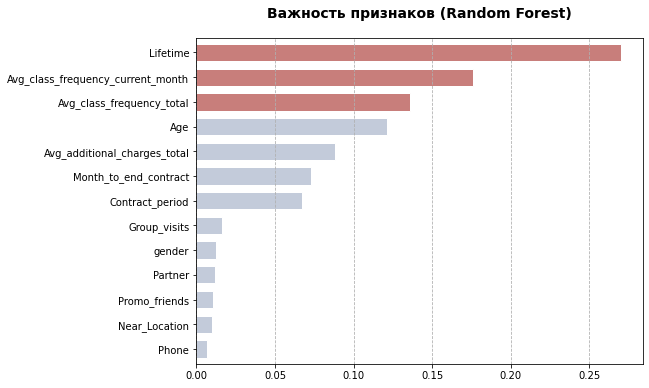

In [10]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

ax = imp.plot.barh(
    figsize=(8, 6),
    color=SOFT_B,
    edgecolor="white",
    width=0.7,
)

# Окрашиваем топ-3
for bar in ax.patches[-3:]:
    bar.set_facecolor(RED)

plt.title("Важность признаков (Random Forest)", fontsize=14, pad=20, fontweight="bold")
plt.grid(axis="x", linestyle="--")
save_fig("03_feature_importance")
plt.show()

> **Как читать важность признаков.** Если два признака несут почти один и тот же сигнал (например, частота посещений за всё время и за последний месяц, корреляция 0.95), лес выбирает на разных деревьях то один, то другой, и вклад «делится» между ними. Поэтому каждый из них по отдельности выглядит слабее, чем фактор «частота посещений» в целом. То же касается `Contract_period` и `Month_to_end_contract`. Рейтинг важности зависит от набора признаков и не является абсолютной истиной.

---
<b>Как читать метрики модели (Random Forest)</b>

<table border="1" cellpadding="6" cellspacing="0" style="border-collapse: collapse; width: 100%;">
  <tr style="background-color:#f2f2f2;">
    <th>Метрика</th>
    <th>Значение</th>
    <th>Как читать</th>
  </tr>
  <tr>
    <td><b>Accuracy</b></td>
    <td>≈ 0.92</td>
    <td>Доля верных предсказаний. 92% звучит хорошо, но классы несбалансированы (<b>73.5%</b> клиентов остаются), поэтому одной этой метрике верить нельзя</td>
  </tr>
  <tr>
    <td><b>Precision</b></td>
    <td>≈ 0.88</td>
    <td>Из тех, кого модель назвала «уйдёт», реально уходят ≈ 88%. Чем выше, тем меньше денег тратится на удержание тех, кто и так остался бы</td>
  </tr>
  <tr>
    <td><b>Recall</b></td>
    <td>≈ 0.83</td>
    <td>Модель находит ≈ 83% всех реально уходящих клиентов. Для задачи удержания это <b>ключевая метрика</b>: пропущенный уходящий клиент — потеря выручки</td>
  </tr>
</table>

<strong>Самые важные признаки</strong>

<ul>
  <li>время с момента первого обращения в фитнес-центр в месяцах;</li>
  <li>частота посещений в последний месяц и за всё время;</li>
  <li>возраст;</li>
  <li>дополнительные траты;</li>
  <li>срок договора.</li>
</ul>

<blockquote>
📌 <b>Вывод:</b> модель хорошо находит уходящих клиентов и при этом редко ошибается, называя «уйдёт» тех, кто остаётся. Основные драйверы оттока — короткий срок жизни клиента, низкая частота посещений и короткий абонемент.
</blockquote>

## Кластеризация клиентов

Столбец с оттоком откладываем в сторону и кластеризуем самих клиентов:

1. стандартизируем признаки (`StandardScaler`);
2. строим матрицу расстояний (`linkage`, метод Уорда) и дендрограмму, чтобы оценить число кластеров;
3. обучаем **K-Means** на 5 кластерах (число кластеров задано условием проекта);
4. сравниваем средние значения признаков и долю оттока по кластерам.

### Дендрограмма

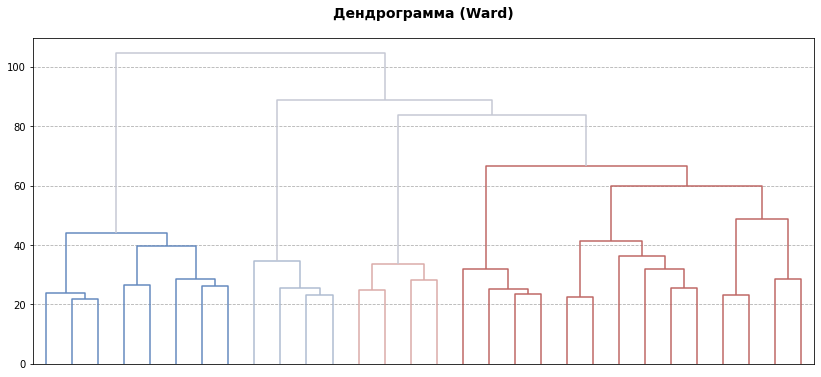

In [11]:
set_link_color_palette([vc(x) for x in (0.12, 0.30, 0.70, 0.88, 0.40)])

# Стандартизация данных
Xs = StandardScaler().fit_transform(X)

# Иерархическая кластеризация методом Уорда
Z = linkage(Xs, method="ward")

# Визуализируем дендрограмму
plt.figure(figsize=(14, 6))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    no_labels=True,
    above_threshold_color="#C5C8D4",
)

plt.title("Дендрограмма (Ward)", fontsize=14, pad=20, fontweight="bold")
plt.grid(axis="y", linestyle="--")
save_fig("04_dendrogram")
plt.show()

---
<b>Что показывает дендрограмма</b>

Чем длиннее вертикальный «ствол» от слияния до слияния, тем сильнее обособлена группа.

1. Самые длинные «стволы» вверху

<table border="1" cellpadding="6" cellspacing="0" style="border-collapse: collapse; width: 100%;">
  <tr style="background-color:#f2f2f2;">
    <th>Группа</th>
    <th>Внутреннее слияние (высота)</th>
    <th>Отделяется / присоединяется (высота)</th>
  </tr>
  <tr>
    <td>Левая (синяя)</td>
    <td>~44</td>
    <td>отделяется от остальных на уровне ~104</td>
  </tr>
  <tr>
    <td>Серая</td>
    <td>~35</td>
    <td>отделяется на уровне ~89</td>
  </tr>
  <tr>
    <td>Розовая</td>
    <td>~33</td>
    <td>присоединяется к красной на уровне ~84</td>
  </tr>
</table>

2. Отсечение на разных высотах

<table border="1" cellpadding="6" cellspacing="0" style="border-collapse: collapse; width: 100%;">
  <tr style="background-color:#f2f2f2;">
    <th>Высота отсечения</th>
    <th>Число групп</th>
    <th>Комментарий</th>
  </tr>
  <tr>
    <td>~70</td>
    <td>4</td>
    <td>синяя, серая, розовая и красная; красная ветвь ещё цельная (её внутреннее слияние идёт на высоте ~66)</td>
  </tr>
  <tr>
    <td>60-65</td>
    <td>5</td>
    <td>красная ветвь делится на две</td>
  </tr>
  <tr>
    <td>&lt;~50</td>
    <td>—</td>
    <td>идёт дробление при небольших расстояниях, новых обособленных групп нет</td>
  </tr>
</table>

<blockquote>
📌 <b>Вывод:</b> по дендрограмме разумно выбирать <b>4-5 кластеров</b>. Договорённость взять <b>5</b> — это верхняя граница естественного разбиения: дальнейшее деление уже не выделяет обособленных групп.
</blockquote>

### K-Means: средние значения признаков по кластерам

In [12]:
# Обучаем K-Means на стандартизированных данных (5 кластеров)
km = KMeans(n_clusters=5, random_state=RANDOM_STATE, n_init=10).fit(Xs)

# Сохраняем номера кластеров в таблицу
df["cluster"] = km.labels_

# Глобальный формат отображения чисел: два знака после запятой
pd.options.display.float_format = "{:.2f}".format

# Средние значения признаков по кластерам
df.groupby("cluster").mean().T

cluster,0,1,2,3,4
gender,0.50,0.52,0.50,0.49,0.56
Near_Location,0.96,0.86,0.00,1.00,0.98
Partner,0.78,0.47,0.46,0.35,0.36
Promo_friends,0.57,0.31,0.08,0.24,0.23
Phone,1.00,0.00,1.00,1.00,1.00
Contract_period,10.89,4.79,2.35,1.95,2.67
Group_visits,0.54,0.43,0.22,0.34,0.47
Age,29.98,29.30,28.48,28.17,30.13
Avg_additional_charges_total,160.76,143.96,135.46,131.62,161.66
Month_to_end_contract,9.95,4.48,2.20,1.86,2.46


### Размер кластеров и доля оттока

In [13]:
# Размеры кластеров и уровень оттока
summary = df.groupby("cluster").agg(
    clients=("Churn", "size"),
    churn_rate=("Churn", "mean"),
)
summary["share"] = summary.clients / len(df)

display_summary = pd.DataFrame({
    "Клиентов": summary["clients"],
    "Доля клиентов, %": (summary["share"] * 100).round(1),
    "Отток, %": (summary["churn_rate"] * 100).round(1),
})
display_summary.index.name = "Кластер"

overall_churn = df["Churn"].mean() * 100

print("=" * 75)
print("Размер кластеров и уровень оттока")
print("=" * 75)
print(display_summary.to_string(
    col_space={"Клиентов": 15, "Доля клиентов, %": 25, "Отток, %": 20},
    formatters={
        "Доля клиентов, %": "{:.1f}".format,
        "Отток, %": "{:.1f}".format,
    },
))
print("-" * 75)
print(f"{'Всего клиентов:':<30} {len(df)}")
print(f"{'Средний отток по базе:':<30} {overall_churn:.1f}%")
print("=" * 75)

Размер кластеров и уровень оттока
               Клиентов          Доля клиентов, %             Отток, %
Кластер                                                               
0                  1010                      25.2                  2.8
1                   385                       9.6                 26.8
2                   505                      12.6                 44.4
3                  1262                      31.6                 51.4
4                   838                      21.0                  6.8
---------------------------------------------------------------------------
Всего клиентов:                4000
Средний отток по базе:         26.5%


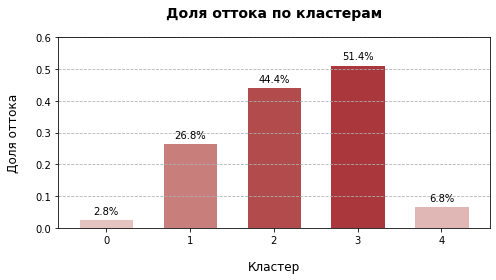

In [14]:
# Цвет столбцов усиливается с ростом оттока
colors = [VLAG(0.62 + 0.38 * v / summary.churn_rate.max()) for v in summary.churn_rate]

ax = summary.churn_rate.plot.bar(
    figsize=(7, 4),
    color=colors,
    edgecolor="white",
    width=0.65,
)

# Подписи значений над столбцами
for rect in ax.patches:
    height = rect.get_height()
    ax.annotate(
        f"{height:.1%}",
        xy=(rect.get_x() + rect.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
    )

plt.ylim(0, 0.6)
ax.set_title("Доля оттока по кластерам", fontsize=14, pad=20, fontweight="bold")
ax.set_xlabel("Кластер", fontsize=12, labelpad=15)
ax.set_ylabel("Доля оттока", fontsize=12, labelpad=15)
ax.grid(axis="y", linestyle="--")
plt.xticks(rotation=0)

plt.tight_layout()
save_fig("05_churn_by_cluster")
plt.show()

---
## Основные выводы

<p>Отток по базе составляет <b>26.5%</b>, и он сильно неравномерен: по кластерам — от <b>2.8%</b> до <b>51.4%</b>. Два кластера (0 и 4, <b>46%</b> клиентов) почти не уходят, а кластер 3 (<b>32%</b> клиентов) теряет каждого второго.</p>

<table border="1" cellpadding="6" cellspacing="0" style="border-collapse: collapse; width: 100%;">
  <tr style="background-color:#f2f2f2;">
    <th>Кластер</th>
    <th>Доля базы</th>
    <th>Отток</th>
    <th>Особенность</th>
  </tr>
  <tr>
    <td>0</td>
    <td>25,2%</td>
    <td>🟢 2.8%</td>
    <td>частота ~2 раза/нед., Lifetime 4.7-4.9 мес.; 78% партнёров, 57% по акции «Приведи друга»</td>
  </tr>
  <tr>
    <td>4</td>
    <td>21,0%</td>
    <td>🟢 6.8%</td>
    <td>частота ~2.85 раза/нед., договор ~2.7 мес.</td>
  </tr>
  <tr>
    <td>1</td>
    <td>9.6%</td>
    <td>🟡 26.8%</td>
    <td>нет контактного телефона — клуб не может связаться с клиентами</td>
  </tr>
  <tr>
    <td>2</td>
    <td>12.6%</td>
    <td>🟠 44.4%</td>
    <td>никто не живёт и не работает рядом; на групповые ходят лишь 22%; договор ~2.4 мес.</td>
  </tr>
  <tr>
    <td>3</td>
    <td>31,6%</td>
    <td>🔴 51.4%</td>
    <td>частота падает с 1.25 до 1.01 раза/нед., Lifetime всего 2.4 мес.; договор ~2 мес.</td>
  </tr>
</table>

<strong>Ключевые закономерности</strong>

<ul>
  <li><b>Главный маркер риска — вовлечённость.</b> Если клиент стал ходить редко, скорее всего, он уже теряет интерес и думает бросить занятия. Сама по себе низкая посещаемость — это еще не причина ухода, но яркий симптом того, что клиент «остыл»;</li>
  <li><b>Короткий договор опасен в сочетании с низкой посещаемостью.</b> Если человек купил абонемент всего на 2.5 месяца, но ходит в зал часто — он останется (уходят всего 6.8%, кластер 4). Но если абонемент короткий и посещаемость низкая — клиент уйдет с вероятностью около 50% (кластеры 3 и 2);</li>
  <li><b>Социальные факторы работают избирательно.</b> Партнёрство и акция «Приведи друга» отлично удерживают самую преданную группу клиентов (кластер 0). Однако сами по себе они не гарантируют успех: есть группы с почти одинаковым количеством друзей и скидок, но в одной уходят 51.4% клиентов (кластер 3), а в другой — только 6.8% (кластер 4);</li>
  <li><b>Близость к клубу важна для отдельной группы.</b> Для определенной категории клиентов решающим фактором становится то, насколько близко от зала они живут или работают (кластер 2);</li>
  <li><b>Проблема с «молчаливой» группой.</b> Есть отдельный тип клиентов, у которых отток умеренный (26,8%, на уровне среднего), а само отсутствие номера никак не влияет на уход (в EDA корреляция наличия телефона с оттоком около нуля). Однако главная проблема в том, что клуб не может напрямую связаться с этими людьми, из-за чего они остаются полностью изолированными от коммуникации (кластер 1).</li>
</ul>

<blockquote>
📌 Модель случайного леса в данном запуске даёт <b>accuracy ≈ 0.92</b>, <b>precision ≈ 0.88</b>, <b>recall ≈ 0.83</b>. Её можно использовать как систему раннего оповещения о клиентах, которые собираются уйти.
</blockquote>

---
## Выводы и рекомендации по удержанию клиентов

1. Главная цель — кластер 3 («Новички на коротком договоре», 32% базы, отток 51%)
<ul>
  <li>Первые 3 месяца: бесплатная персональная тренировка и составление плана в первые 2 недели;</li>
  <li>Звонок или сообщение куратора на 3-й и 6-й неделе;</li>
  <li>Челлендж «12 тренировок за первый месяц» с призом;</li>
  <li>Скидка при переходе с короткого абонемента на 6- или 12-месячный.</li>
</ul>


2. Реагировать на падение посещаемости
<ul>
  <li>Модель или простое правило (частота ниже ~1 раза в неделю) запускает автоматическое сообщение с персональным предложением;</li>
  <li>Примеры предложений: бесплатное занятие, напиток в кафе, сеанс массажа;</li>
  <li>Для самых рискованных клиентов — звонок менеджера;</li>
  <li>Предложить «заморозку» абонемента вместо ухода.</li>
</ul>


3. Отдельные меры для «далёких» (кластер 2, 12.6% базы, отток 44%)
<ul>
  <li>Гибкие тарифы: утренние, вечерние или «только в рабочие дни»;</li>
  <li>Онлайн-тренировки и видеоуроки;</li>
  <li>Партнёрства с компаниями и фитнес-точками в других районах;</li>
  <li>Групповые занятия там, где это возможно (сейчас ходят только 22% кластера).</li>
</ul>


4. Собирать контакты (кластер 1, без телефона, 9.6% базы)
<ul>
  <li>Сделать телефон обязательным при оформлении или продлении абонемента;</li>
  <li>Мотивация: бонус или скидка за подтверждение контактов;</li>
  <li>Пока контакта нет — использовать другие каналы (приложение, e-mail, напоминание на ресепшене);</li>
  <em>Сбор телефона сам по себе отток не снижает. Он нужен как условие, чтобы применять к этой группе меры из принципов 1–3: напоминания при падении посещаемости, персональные предложения, звонок куратора.</em>
</ul>


5. Беречь и использовать надёжные кластеры (0 и 4)
<ul>
  <li>Не тратить на них акции удержания — оставить обычное обслуживание;</li>
  <li><b>Кластер 4</b> (высокая посещаемость, короткие договоры) — кандидаты на перевод на длинный абонемент со скидкой: низкий риск и высокая вероятность согласия;</li>
  <li><b>Кластер 0</b> — основа для программы «Приведи друга» и корпоративных предложений: бонусы обоим и расширение партнёрских тарифов.</li>
</ul>

<blockquote>
📌 <b>Приоритет бюджета:</b> кластер 3 (самый большой и самый рискованный) → кластер 2 → кластер 1. Кластеры 0 и 4 нужны как «эталон» поведения и как источник новых клиентов.
</blockquote>